## 📐 1. Formulasi Matematis Metrik Jarak & Prinsip DBSCAN

| Metrik | Rumus jarak |
| --- | --- |
| Euclidean | $d(x,y)=\sqrt{\sum_i(x_i-y_i)^2}$ |
| Manhattan | $d(x,y)=\sum_i|x_i-y_i|$ |
| Cosine | $d(x,y)=1-\frac{x\cdot y}{\lVert x\rVert_2\lVert y\rVert_2}$ |

DBSCAN membentuk klaster dari lingkungan padat:
$$N_\varepsilon(x)=\{y:d(x,y)\leq\varepsilon\},\qquad
|N_\varepsilon(x)|\geq\mathrm{min\_samples}.$$
Label `-1` menunjukkan noise. Semua metrik menggunakan seluruh baris dan
fitur hasil StandardScaler, serta `EPS`, `MIN_SAMPLES`, `algorithm`, dan
`n_jobs` yang sama. PCA menggunakan koordinat yang sama untuk visualisasi.

In [1]:
# =======================================================================
# 1. SETUP & IMPORT LIBRARY
# =======================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11
plt.rcParams['figure.dpi'] = 120

import gc
import time
import tracemalloc

from sklearn.metrics import pairwise_distances

from sklearn.neighbors import NearestNeighbors
from sklearn import config_context


In [2]:
# =======================================================================
# 2. DATASET & PREPROCESSING BERSAMA
# =======================================================================
FILE = 'dataset_B_05_2020 (1).csv'
df = pd.read_csv(FILE)

print('Shape dataset:', df.shape)
print('Jumlah data:', df.shape[0])
print('Jumlah kolom:', df.shape[1])
display(df.head(3))

# Metadata dan label asli disimpan terpisah dari fitur clustering.
urls = df['url'].copy()
y_true = df['status'].copy()
labels = y_true.copy()
X = df.drop(columns=['url', 'status']).select_dtypes(include=np.number)
print('Shape fitur numerik:', X.shape)

# Imputasi median, penghapusan fitur konstan, lalu StandardScaler.
print('Missing value sebelum imputasi:', int(X.isna().sum().sum()))
X = X.fillna(X.median())
print('Missing value setelah imputasi:', int(X.isna().sum().sum()))

selector = VarianceThreshold(threshold=0)
X_sel = selector.fit_transform(X)
selected_features = X.columns[selector.get_support()]
removed_features = X.columns[~selector.get_support()]
X_selected = pd.DataFrame(X_sel, columns=selected_features, index=X.index)
print('Fitur konstan yang dihapus:', list(removed_features))
print('Shape setelah seleksi fitur:', X_selected.shape)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_selected)
df_after = pd.DataFrame(X_scaled, columns=selected_features, index=X.index)
print('Shape setelah StandardScaler:', X_scaled.shape)
display(df_after.head(3))


Shape dataset: (11430, 89)
Jumlah data: 11430
Jumlah kolom: 89


,url,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_or,...,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank,status
0,http://www.crestonwood.com/router.php,37,19,0,3,0,0,0,0,0,...,0,1,0,45,-1,0,1,1,4,legitimate
1,http://shadetreetechnology.com/V4/validation/a...,77,23,1,1,0,0,0,0,0,...,1,0,0,77,5767,0,0,1,2,phishing
2,https://support-appleld.com.secureupdate.duila...,126,50,1,4,1,0,1,2,0,...,1,0,0,14,4004,5828815,0,1,0,phishing


Shape fitur numerik: (11430, 87)
Missing value sebelum imputasi: 0
Missing value setelah imputasi: 0
Fitur konstan yang dihapus: ['nb_or', 'ratio_nullHyperlinks', 'ratio_intRedirection', 'ratio_intErrors', 'submit_email', 'sfh']
Shape setelah seleksi fitur: (11430, 81)
Shape setelah StandardScaler: (11430, 81)


,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_eq,nb_underscore,...,empty_title,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank
0,-0.436327,-0.193964,-0.421020,0.379116,-0.477984,-0.142915,-0.387464,-0.197604,-0.293683,-0.295128,...,-0.377549,-1.860473,1.129194,-0.28037,-0.549299,-1.307594,-0.429340,6.978227,0.934264,0.320974
1,0.287067,0.177207,2.375182,-1.081136,-0.477984,-0.142915,-0.387464,-0.197604,-0.293683,-0.295128,...,-0.377549,0.537498,-0.885587,-0.28037,-0.510022,0.548471,-0.429340,-0.143303,0.934264,-0.467407
2,1.173224,2.682613,2.375182,1.109242,0.001174,-0.142915,2.356473,2.237556,2.711505,1.534217,...,-0.377549,0.537498,-0.885587,-0.28037,-0.587348,-0.018839,2.491612,-0.143303,0.934264,-1.255788


### Contoh jarak menggunakan library

Jarak P0, P1, dan P2 dihitung dengan `pairwise_distances` pada koordinat
StandardScaler yang sama. Rincian per fitur tersedia di notebook masing-masing metrik.


In [3]:
EXAMPLE_NODES = [0, 1, 2]
example_rows = []
for a, b in [(0, 1), (0, 2), (1, 2)]:
    row = {'Pasangan': f'P{a} - P{b}'}
    for metric in ['euclidean', 'manhattan', 'cosine']:
        row[metric] = pairwise_distances(X_scaled[a:a + 1], X_scaled[b:b + 1], metric=metric)[0, 0]
    example_rows.append(row)
pair_distance_df = pd.DataFrame(example_rows)
display(pair_distance_df.round(8))


,Pasangan,euclidean,manhattan,cosine
0,P0 - P1,13.059100,58.498862,1.162640
1,P0 - P2,14.384229,73.599151,1.174413
2,P1 - P2,11.554632,52.856607,0.863533


## 📈 2. Parameter DBSCAN dan K-Distance Plot

Seluruh metrik memakai `EPS = 0.5`, `MIN_SAMPLES = 5`, `algorithm="brute"`, dan `n_jobs=1`.
K-Distance Plot menunjukkan kandidat eps untuk belajar; parameter fit tetap sama.

Waktu dan puncak alokasi `tracemalloc` diukur selama `fit_predict()`. K-distance, contoh perhitungan, Silhouette, dan PCA berada di luar pengukuran fit. Memori dalam MiB adalah alokasi terlacak, bukan total RSS proses. Silhouette memakai semua data non-noise ketika jumlah klaster memenuhi syarat.


In [4]:
# =======================================================================
# 3. PARAMETER PENGUJIAN TIGA METRIK
# =======================================================================
DISTANCE_METRICS = [
    "euclidean",
    "manhattan",
    "cosine",
]

EPS = 0.5
MIN_SAMPLES = 5

print("Distance metrics :", DISTANCE_METRICS)
print("EPS              :", EPS)
print("MIN_SAMPLES      :", MIN_SAMPLES)


Distance metrics : ['euclidean', 'manhattan', 'cosine']
EPS              : 0.5
MIN_SAMPLES      : 5


### K-Distance Plot untuk membaca kandidat `eps`

Dengan `MIN_SAMPLES = 5`, sebuah core point perlu lima anggota lingkungan,
**termasuk dirinya sendiri**. `kneighbors(X_scaled)` memasukkan jarak nol
ke titik query; kolom terakhir dari lima jarak terdekat adalah jarak ke
tetangga keempat selain dirinya (duplikat juga dihitung sebagai baris).
Jarak tersebut dihitung untuk setiap node, diurutkan menaik, lalu diplot.

Siku kurva memberikan **kandidat** `eps`, bukan jaminan parameter optimal.
Penanda memakai jarak terbesar antara kurva yang dinormalisasi dan garis
penghubung kedua ujung; kurva datar tidak diberi kandidat. Periksa bentuk
kurva dan hasil klaster sebelum memakai kandidat tersebut.

Untuk studi perbandingan ini, **`EPS = 0.5` tetap digunakan pada semua
metrik**, bersama `MIN_SAMPLES`, `algorithm`, dan `n_jobs` yang sama.
Kandidat dari plot tidak mengganti parameter fit. Nilai numerik `eps`
yang sama mempunyai skala/geometri berbeda pada Euclidean, Manhattan,
dan Cosine, sehingga ini membandingkan perilaku dengan parameter tetap.

Jarak ke titik sendiri dapat tampil sebagai angka sangat kecil karena
presisi floating point; secara matematis nilainya nol.

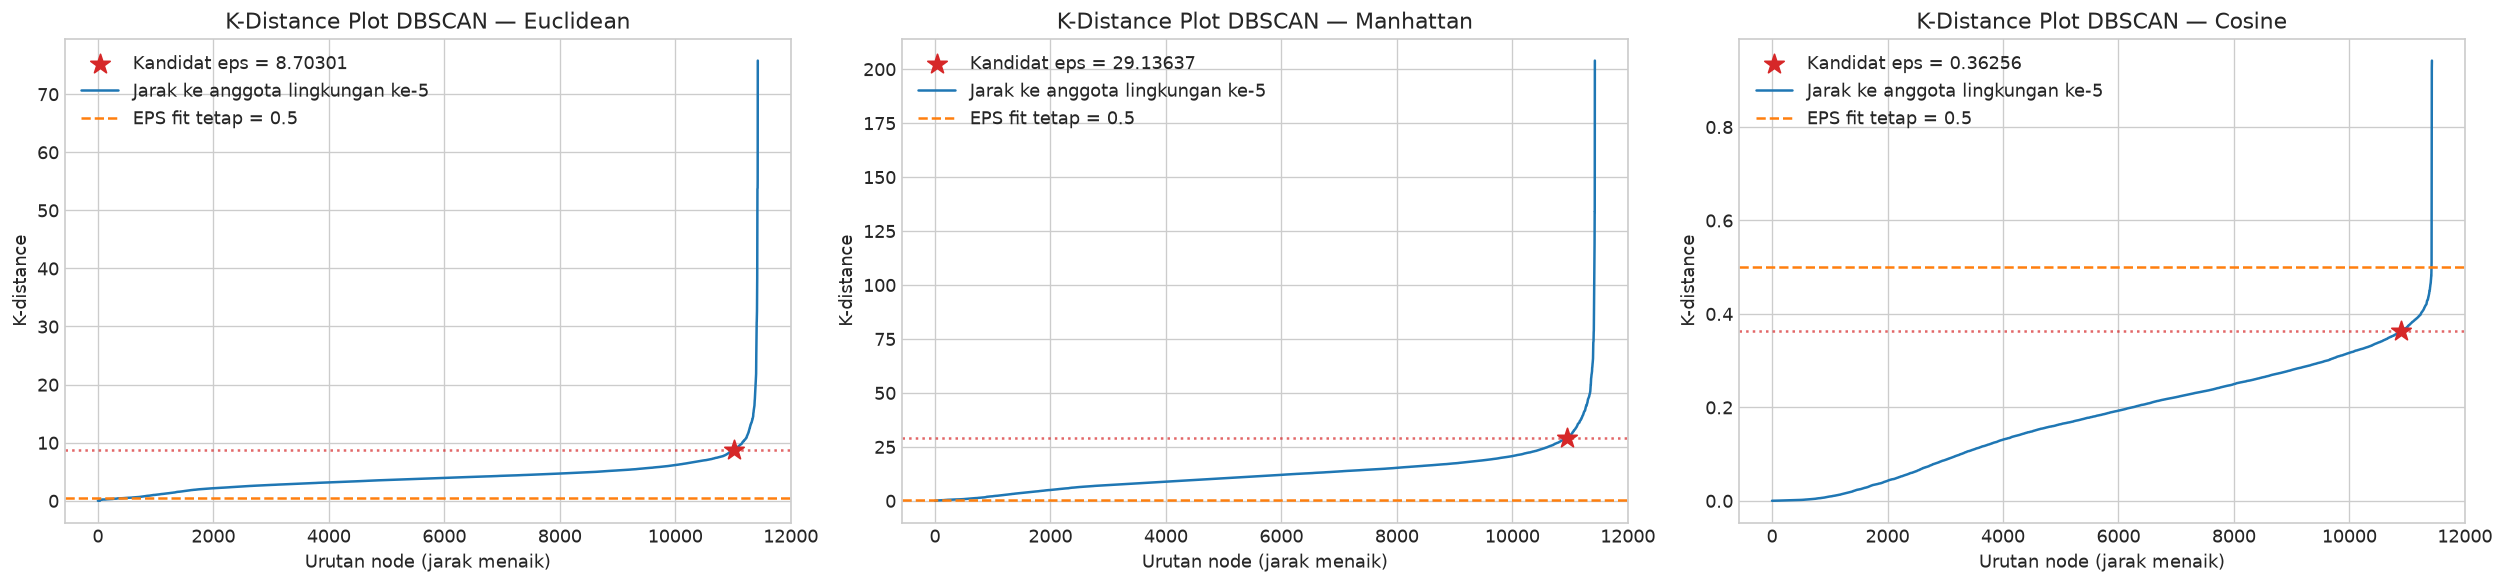

,Metrik,MIN_SAMPLES (termasuk sendiri),k (selain sendiri),Kandidat eps (heuristik),EPS untuk fit
0,euclidean,5,4,8.703006,0.5
1,manhattan,5,4,29.136368,0.5
2,cosine,5,4,0.362558,0.5


Contoh urutan tetangga P0, P1, P2; jarak terakhir menjadi nilai K-distance node tersebut.
Pada jarak seri/duplikat, ID tetangga yang dipilih dapat berbeda; nilai jaraknya tetap sama.


,Metrik,Node query,Urutan,Node tetangga,Jarak,Dalam EPS
0,euclidean,P0,1,P0,0.000000e+00,True
1,euclidean,P0,2,P9333,5.609147e+00,False
2,euclidean,P0,3,P4886,5.697852e+00,False
3,euclidean,P0,4,P2872,5.998942e+00,False
4,euclidean,P0,5,P5912,6.228467e+00,False
5,euclidean,P1,1,P1,1.200000e-07,True
6,euclidean,P1,2,P1651,1.453407e-01,True
7,euclidean,P1,3,P766,2.097032e-01,True
8,euclidean,P1,4,P3406,4.361937e-01,True
9,euclidean,P1,5,P289,4.438671e-01,True


In [5]:
# Semua node digunakan; blok query membatasi memori matriks jarak sementara.
plot_metrics = DISTANCE_METRICS if 'DISTANCE_METRICS' in globals() else [DISTANCE_METRIC]
k_distance_by_metric = {}
knee_eps_by_metric = {}
neighbor_examples = []
fig, axes = plt.subplots(1, len(plot_metrics), figsize=(7 * len(plot_metrics), 5), squeeze=False)
for ax, metric in zip(axes.ravel(), plot_metrics):
    nn = NearestNeighbors(n_neighbors=MIN_SAMPLES, metric=metric,
                          algorithm='brute', n_jobs=1).fit(X_scaled)
    # X diberikan secara eksplisit: hitungan mencakup jarak nol ke titik sendiri.
    with config_context(working_memory=128):
        distances, indices = nn.kneighbors(X_scaled)
    k_distances = np.sort(distances[:, -1])
    k_distance_by_metric[metric] = k_distances
    rank = np.arange(len(k_distances))
    candidate = np.nan
    if np.ptp(k_distances) > 0:
        x_norm = rank / (len(rank) - 1)
        y_norm = (k_distances - k_distances[0]) / np.ptp(k_distances)
        gap = x_norm - y_norm
        knee_index = int(np.argmax(gap))
        if 0 < knee_index < len(rank) - 1 and gap[knee_index] > 1e-6:
            candidate = float(k_distances[knee_index])
            ax.scatter(knee_index, candidate, color='tab:red', marker='*', s=150,
                       zorder=3, label=f'Kandidat eps = {candidate:.5f}')
            ax.axhline(candidate, color='tab:red', ls=':', alpha=0.7)
    knee_eps_by_metric[metric] = candidate
    ax.plot(rank, k_distances, label=f'Jarak ke anggota lingkungan ke-{MIN_SAMPLES}')
    ax.axhline(EPS, color='tab:orange', ls='--', label=f'EPS fit tetap = {EPS}')
    ax.set(xlabel='Urutan node (jarak menaik)', ylabel='K-distance',
           title=f'K-Distance Plot DBSCAN — {metric.title()}')
    ax.legend()
    for node in EXAMPLE_NODES:
        for j in range(MIN_SAMPLES):
            neighbor_examples.append({'Metrik': metric, 'Node query': f'P{node}',
                'Urutan': j + 1, 'Node tetangga': f'P{indices[node, j]}',
                'Jarak': distances[node, j], 'Dalam EPS': distances[node, j] <= EPS})
    del nn, distances, indices
plt.tight_layout()
plt.show()
display(pd.DataFrame([{'Metrik': m, 'MIN_SAMPLES (termasuk sendiri)': MIN_SAMPLES,
    'k (selain sendiri)': MIN_SAMPLES - 1,
    'Kandidat eps (heuristik)': knee_eps_by_metric[m], 'EPS untuk fit': EPS}
    for m in plot_metrics]).round(6))
print('Contoh urutan tetangga P0, P1, P2; jarak terakhir menjadi nilai K-distance node tersebut.')
print('Pada jarak seri/duplikat, ID tetangga yang dipilih dapat berbeda; nilai jaraknya tetap sama.')
display(pd.DataFrame(neighbor_examples).round(8))


In [6]:
# =======================================================================
# 4. FUNGSI BENCHMARK DBSCAN
# =======================================================================
def benchmark_dbscan(X_data, metric, eps, min_samples):
    gc.collect()

    model = DBSCAN(
        eps=eps,
        min_samples=min_samples,
        metric=metric,
        algorithm="brute",
        n_jobs=1
    )

    tracemalloc.start()
    start_time = time.perf_counter()

    cluster_labels = model.fit_predict(X_data)

    execution_time = time.perf_counter() - start_time
    _, peak_memory = tracemalloc.get_traced_memory()
    tracemalloc.stop()

    peak_memory_mb = peak_memory / (1024 ** 2)

    noise_mask = cluster_labels == -1
    n_clusters = len(set(cluster_labels)) - int(noise_mask.any())

    X_evaluation = X_data[~noise_mask]
    labels_evaluation = cluster_labels[~noise_mask]
    n_evaluation_clusters = len(np.unique(labels_evaluation))

    silhouette = np.nan

    if (
        len(labels_evaluation) > 1
        and 2 <= n_evaluation_clusters < len(labels_evaluation)
    ):
        silhouette = silhouette_score(
            X_evaluation,
            labels_evaluation,
            metric=metric
        )

    core_mask = np.zeros(len(cluster_labels), dtype=bool)
    core_mask[model.core_sample_indices_] = True
    border_mask = (~noise_mask) & (~core_mask)

    result = {
        "Distance Metric": metric.title(),
        "EPS": eps,
        "MIN_SAMPLES": min_samples,
        "Algorithm": "brute",
        "n_jobs": 1,
        "Jumlah Kluster": n_clusters,
        "Core Point": int(core_mask.sum()),
        "Border Point": int(border_mask.sum()),
        "Noise": int(noise_mask.sum()),
        "Noise (%)": 100 * noise_mask.mean(),
        "Waktu Eksekusi (detik)": execution_time,
        "Silhouette Score": silhouette,
        "Penggunaan Memori (MiB)": peak_memory_mb,
    }

    return result, cluster_labels, core_mask


In [7]:
# =======================================================================
# 5. EKSEKUSI CLUSTERING & TABEL PERBANDINGAN
# =======================================================================
results = []
cluster_labels_by_metric = {}
core_mask_by_metric = {}

for metric in DISTANCE_METRICS:
    print(f"Menjalankan DBSCAN dengan metric = {metric} ...")

    result, cluster_labels, metric_core = benchmark_dbscan(
        X_data=X_scaled,
        metric=metric,
        eps=EPS,
        min_samples=MIN_SAMPLES
    )

    results.append(result)
    cluster_labels_by_metric[metric] = cluster_labels
    core_mask_by_metric[metric] = metric_core

print("Selesai.")

comparison_df = pd.DataFrame(results)

comparison_df["Waktu Eksekusi (detik)"] = (
    comparison_df["Waktu Eksekusi (detik)"].round(4)
)

comparison_df["Silhouette Score"] = (
    comparison_df["Silhouette Score"].round(4)
)

comparison_df["Penggunaan Memori (MiB)"] = (
    comparison_df["Penggunaan Memori (MiB)"].round(4)
)

display(comparison_df)


Menjalankan DBSCAN dengan metric = euclidean ...


Menjalankan DBSCAN dengan metric = manhattan ...


Menjalankan DBSCAN dengan metric = cosine ...


Selesai.


,Distance Metric,EPS,MIN_SAMPLES,Algorithm,n_jobs,Jumlah Kluster,Core Point,Border Point,Noise,Noise (%),Waktu Eksekusi (detik),Silhouette Score,Penggunaan Memori (MiB)
0,Euclidean,0.5,5,brute,1,58,509,120,10801,94.496938,0.1853,0.6842,16.1451
1,Manhattan,0.5,5,brute,1,30,277,79,11074,96.885389,2.3841,0.8311,15.9662
2,Cosine,0.5,5,brute,1,5,11422,2,6,0.052493,1.0192,-0.0097,2381.4033


### Dari perhitungan jarak menuju core, border, dan noise

Untuk P0, P1, dan P2, hitung jarak ke **semua baris** lalu hitung yang
memenuhi $d\leq\mathrm{EPS}$. Titik sendiri dihitung dengan jarak nol.
Jika jumlahnya mencapai `MIN_SAMPLES`, node menjadi core point. Node
non-core menjadi border jika bertetangga dengan core point; selebihnya
noise. Label klaster mengikuti koneksi antarlingkungan core point.
Tabel di bawah menghubungkan hitungan ini dengan label hasil fit.

In [8]:
def jelaskan_node_dbscan(metric, node_labels, node_core):
    D = pairwise_distances(X_scaled[EXAMPLE_NODES], X_scaled, metric=metric)
    for row, node in enumerate(EXAMPLE_NODES):
        D[row, node] = 0.0
    ringkasan = []
    for row, node in enumerate(EXAMPLE_NODES):
        dalam_eps = D[row] <= EPS
        jumlah = int(dalam_eps.sum())
        np.testing.assert_equal(jumlah >= MIN_SAMPLES, bool(node_core[node]))
        tipe = 'core' if node_core[node] else ('noise' if node_labels[node] == -1 else 'border')
        ringkasan.append({'Metrik': metric, 'Node': f'P{node}',
            'Tetangga dalam EPS (termasuk sendiri)': jumlah,
            'MIN_SAMPLES': MIN_SAMPLES, 'Core?': jumlah >= MIN_SAMPLES,
            'Tipe hasil fit': tipe, 'Label hasil fit': int(node_labels[node])})
    display(pd.DataFrame(ringkasan))

for metric in DISTANCE_METRICS:
    jelaskan_node_dbscan(metric, cluster_labels_by_metric[metric], core_mask_by_metric[metric])


,Metrik,Node,Tetangga dalam EPS (termasuk sendiri),MIN_SAMPLES,Core?,Tipe hasil fit,Label hasil fit
0,euclidean,P0,1,5,False,noise,-1
1,euclidean,P1,7,5,True,core,0
2,euclidean,P2,7,5,True,core,1


,Metrik,Node,Tetangga dalam EPS (termasuk sendiri),MIN_SAMPLES,Core?,Tipe hasil fit,Label hasil fit
0,manhattan,P0,1,5,False,noise,-1
1,manhattan,P1,4,5,False,border,5
2,manhattan,P2,4,5,False,border,7


,Metrik,Node,Tetangga dalam EPS (termasuk sendiri),MIN_SAMPLES,Core?,Tipe hasil fit,Label hasil fit
0,cosine,P0,108,5,True,core,0
1,cosine,P1,283,5,True,core,0
2,cosine,P2,374,5,True,core,0


Explained variance PC1 + PC2: 0.1551
PC1: 0.1014
PC2: 0.0537


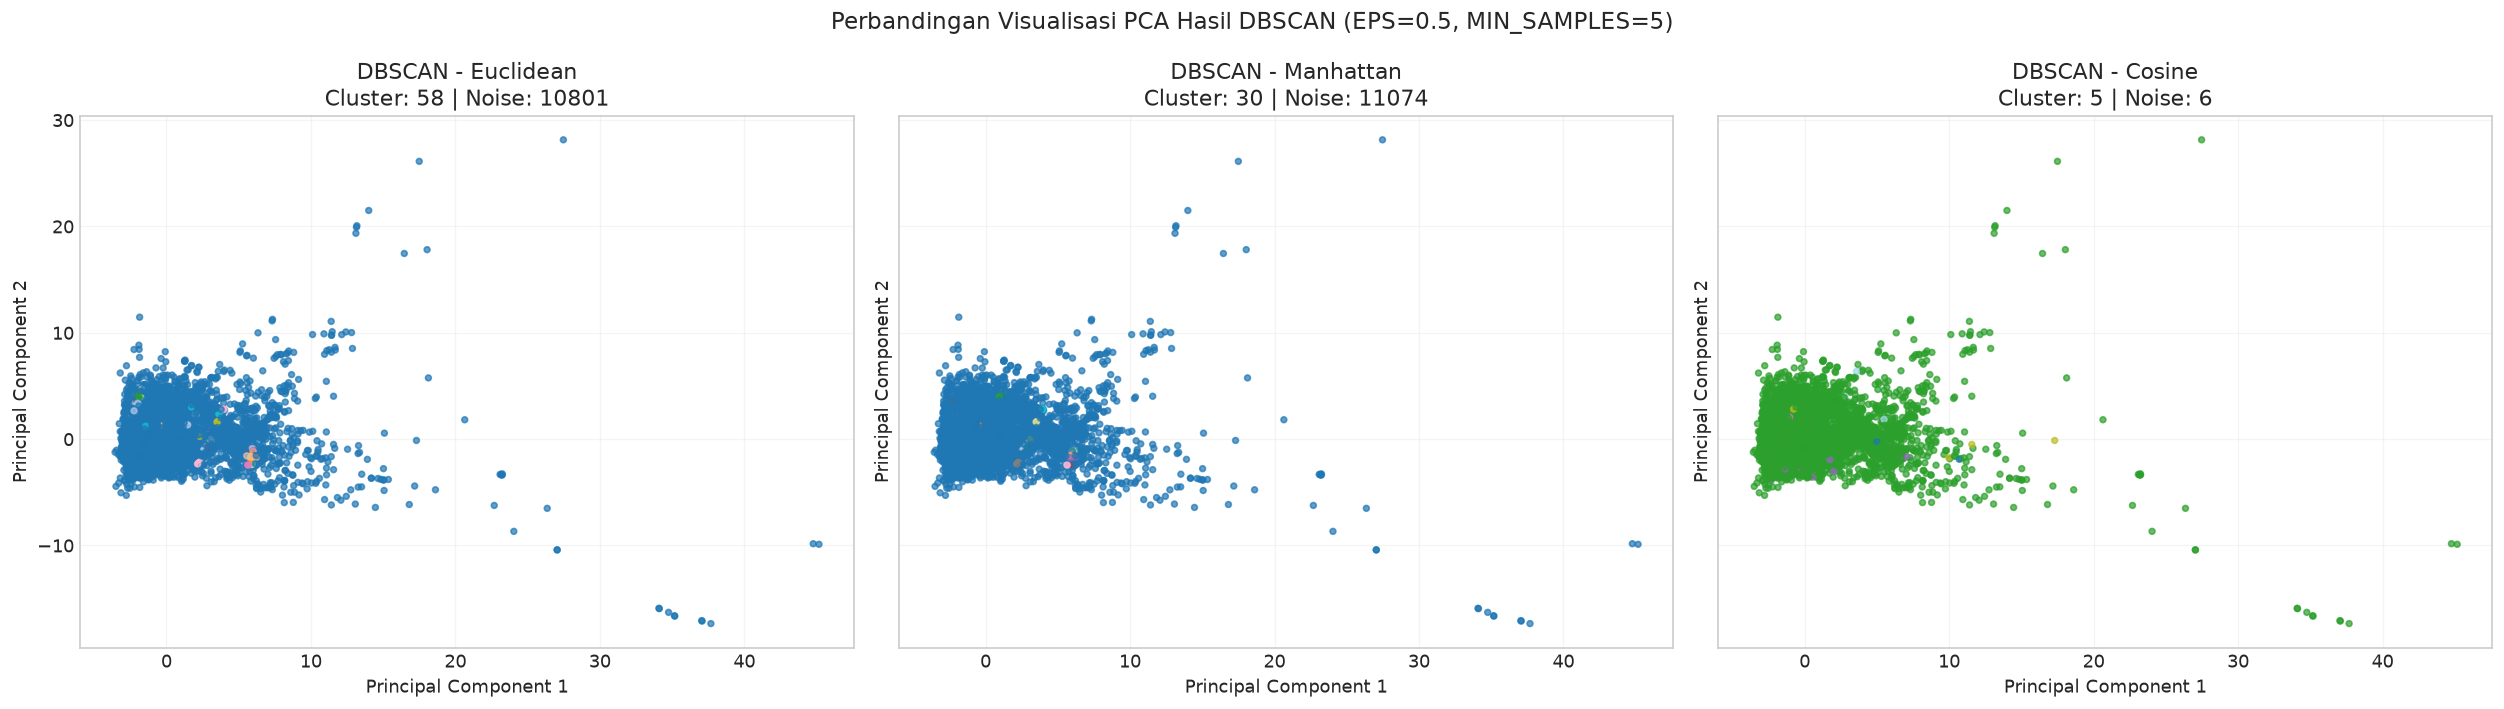

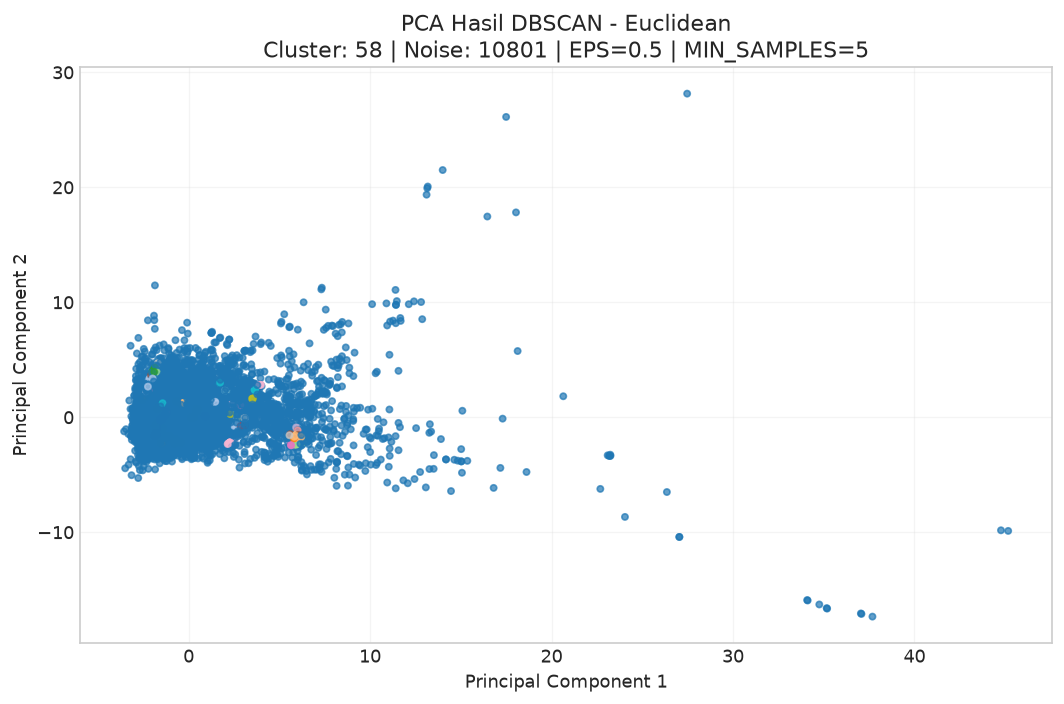

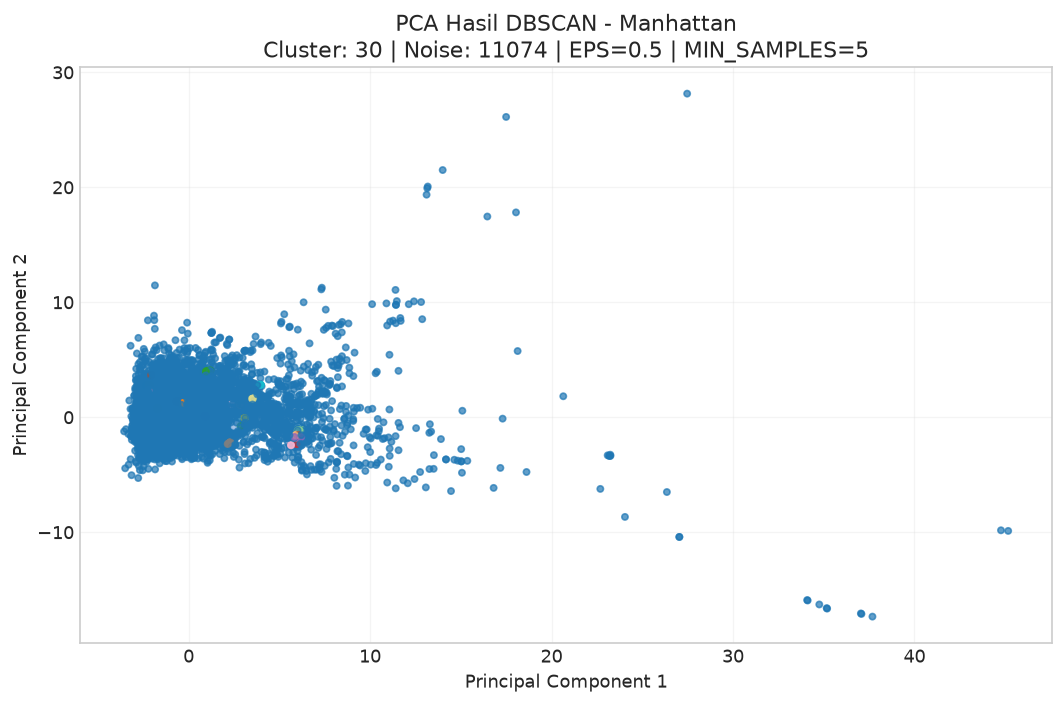

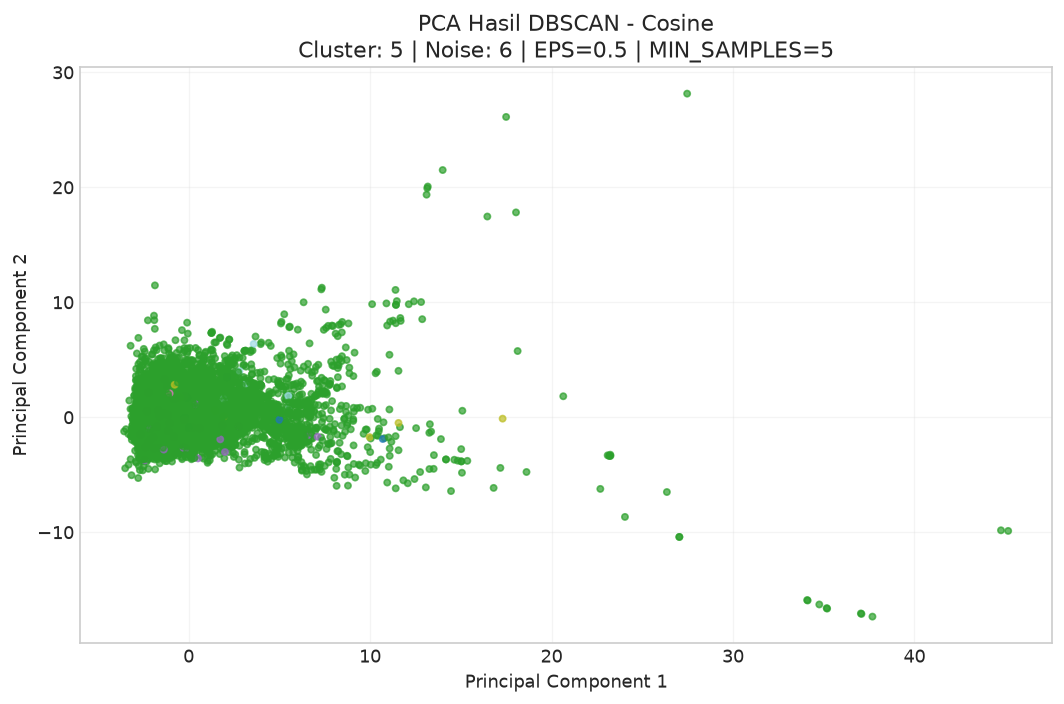

In [9]:
# =======================================================================
# 6. VISUALISASI PCA 2D PERBANDINGAN KLASTER & NOISE
# =======================================================================
pca = PCA(n_components=2, svd_solver="full", random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

print("Explained variance PC1 + PC2:", round(pca.explained_variance_ratio_.sum(), 4))
print("PC1:", round(pca.explained_variance_ratio_[0], 4))
print("PC2:", round(pca.explained_variance_ratio_[1], 4))

fig, axes = plt.subplots(1, 3, figsize=(21, 6), sharex=True, sharey=True)

for ax, metric in zip(axes, DISTANCE_METRICS):
    cluster_labels = cluster_labels_by_metric[metric]

    scatter = ax.scatter(
        X_pca[:, 0],
        X_pca[:, 1],
        c=cluster_labels,
        cmap="tab20",
        s=12,
        alpha=0.7
    )

    n_clusters = len(set(cluster_labels)) - int(-1 in cluster_labels)
    n_noise = np.sum(cluster_labels == -1)

    ax.set_title(
        f"DBSCAN - {metric.title()}\n"
        f"Cluster: {n_clusters} | Noise: {n_noise}"
    )
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")
    ax.grid(alpha=0.2)

plt.suptitle(
    f"Perbandingan Visualisasi PCA Hasil DBSCAN "
    f"(EPS={EPS}, MIN_SAMPLES={MIN_SAMPLES})",
    fontsize=14
)
plt.tight_layout()
plt.show()

for metric in DISTANCE_METRICS:
    cluster_labels = cluster_labels_by_metric[metric]
    n_clusters = len(set(cluster_labels)) - int(-1 in cluster_labels)
    n_noise = np.sum(cluster_labels == -1)

    plt.figure(figsize=(9, 6))
    plt.scatter(
        X_pca[:, 0],
        X_pca[:, 1],
        c=cluster_labels,
        cmap="tab20",
        s=14,
        alpha=0.7
    )
    plt.title(
        f"PCA Hasil DBSCAN - {metric.title()}\n"
        f"Cluster: {n_clusters} | Noise: {n_noise} | "
        f"EPS={EPS} | MIN_SAMPLES={MIN_SAMPLES}"
    )
    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()


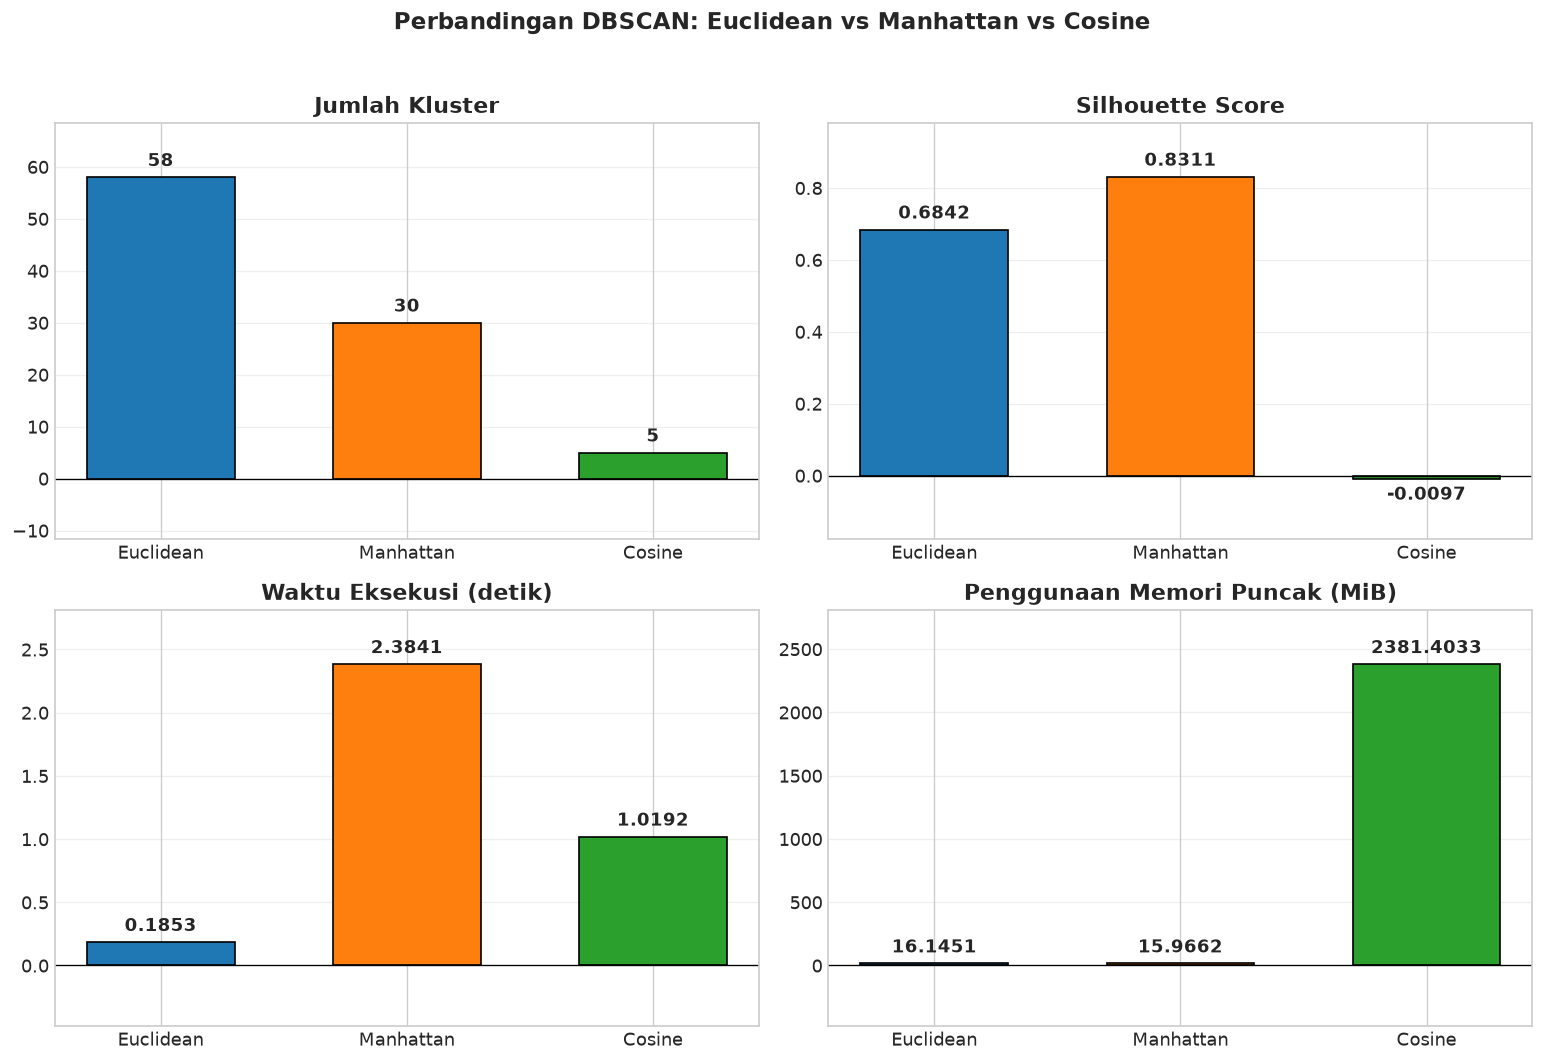

In [10]:
# =======================================================================
# 7. DIAGRAM BATANG PERBANDINGAN EVALUASI & KINERJA
# =======================================================================
# Urutan dan warna mengikuti notebook referensi
nama = comparison_df["Distance Metric"].tolist()
warna = ["tab:blue", "tab:orange", "tab:green"]

panel = [
    ("Jumlah Kluster", "Jumlah Kluster", "{:.0f}"),
    ("Silhouette Score", "Silhouette Score", "{:.4f}"),
    ("Waktu Eksekusi (detik)", "Waktu Eksekusi (detik)", "{:.4f}"),
    ("Penggunaan Memori (MiB)", "Penggunaan Memori Puncak (MiB)", "{:.4f}"),
]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, (kolom, judul, fmt) in zip(axes.ravel(), panel):
    nilai = comparison_df[kolom].to_numpy(dtype=float)

    bars = ax.bar(
        nama,
        np.where(np.isfinite(nilai), nilai, 0),
        color=warna,
        edgecolor="black",
        width=0.6
    )

    ax.set_title(judul, fontweight="bold")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.grid(axis="y", alpha=0.3)

    nilai_valid = nilai[np.isfinite(nilai)]
    if len(nilai_valid) > 0:
        batas = max(np.max(np.abs(nilai_valid)), 1e-9)
        ymin = min(0, np.min(nilai_valid)) - 0.20 * batas
        ymax = np.max(nilai_valid) + 0.18 * batas
        if np.isclose(ymin, ymax):
            ymax = ymin + 1
        ax.set_ylim(ymin, ymax)

    for bar, value in zip(bars, nilai):
        if np.isfinite(value):
            ax.annotate(
                fmt.format(value),
                (bar.get_x() + bar.get_width() / 2, value),
                ha="center",
                va="bottom" if value >= 0 else "top",
                xytext=(0, 4 if value >= 0 else -4),
                textcoords="offset points",
                fontweight="bold"
            )
        else:
            ax.annotate(
                "N/A",
                (bar.get_x() + bar.get_width() / 2, 0),
                ha="center",
                va="bottom",
                xytext=(0, 4),
                textcoords="offset points",
                fontweight="bold"
            )

fig.suptitle(
    "Perbandingan DBSCAN: Euclidean vs Manhattan vs Cosine",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


In [11]:
# =======================================================================
# 8. INTERPRETASI HASIL PERBANDINGAN
# =======================================================================
print('INTERPRETASI HASIL PERBANDINGAN DBSCAN')
for _, row in comparison_df.iterrows():
    score = row['Silhouette Score']
    score_text = f'{score:.4f}' if np.isfinite(score) else 'N/A (jumlah klaster non-noise tidak memenuhi syarat)'
    print(f"{row['Distance Metric']}: {int(row['Jumlah Kluster'])} klaster, "
          f"{int(row['Noise'])} noise ({row['Noise (%)']:.2f}%), Silhouette = {score_text}")
print('Silhouette tiap baris memakai geometri metriknya sendiri; jumlah data non-noise dapat berbeda.')
print('Waktu fit tidak mencakup Silhouette. Memori merupakan peak tracked memory tracemalloc dalam MiB.')
print('PCA hanya untuk visualisasi; proses clustering memakai seluruh fitur setelah StandardScaler.')


INTERPRETASI HASIL PERBANDINGAN DBSCAN
Euclidean: 58 klaster, 10801 noise (94.50%), Silhouette = 0.6842
Manhattan: 30 klaster, 11074 noise (96.89%), Silhouette = 0.8311
Cosine: 5 klaster, 6 noise (0.05%), Silhouette = -0.0097
Silhouette tiap baris memakai geometri metriknya sendiri; jumlah data non-noise dapat berbeda.
Waktu fit tidak mencakup Silhouette. Memori merupakan peak tracked memory tracemalloc dalam MiB.
PCA hanya untuk visualisasi; proses clustering memakai seluruh fitur setelah StandardScaler.
